# Expected SARSA

Expected SARSA averages over the next epsilon-greedy action distribution instead of drawing a single bootstrap action.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Action values

A training run starts with empty value estimates. The behaviour policy explores throughout training.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.gridworld import (
    S,
    A,
    GAMMA,
    START,
    choose,
    step,
    q_from_v,
    exact_values,
    policy_report,
)


def train(seed):
    rng = np.random.default_rng(seed)
    q = np.zeros((S, A))
    trace = []
    for episode in range(650):
        epsilon = max(0.07, 0.7 / (1 + episode / 100))
        state = START
        total = 0.0
        action = choose(q[state], epsilon, rng)
        for _ in range(60):
            nxt, r, done = step(state, action, rng)
            next_action = choose(q[nxt], epsilon, rng)
            continuation = (1 - epsilon) * q[nxt].max() + epsilon * q[nxt].mean()
            target = r if done else r + GAMMA * continuation
            q[state, action] += 0.16 * (target - q[state, action])
            total += r
            state, action = nxt, next_action
            if done:
                break
        trace.append(total)
    return q.argmax(1), trace

## Three training runs

Each final greedy policy plays 240 evaluation episodes on a common independent random stream.

Seed 17: mean return 0.691, goal 100.0%, pit 0.0%, mean steps 8.7, exact discounted start value 0.413
Seed 29: mean return 0.691, goal 100.0%, pit 0.0%, mean steps 8.7, exact discounted start value 0.413
Seed 53: mean return 0.668, goal 98.3%, pit 1.7%, mean steps 8.5, exact discounted start value 0.416
Random policy: mean return -1.715, goal 15.8%, pit 70.0%, mean steps 30.2
Across training seeds: mean return 0.683, sample SD 0.013


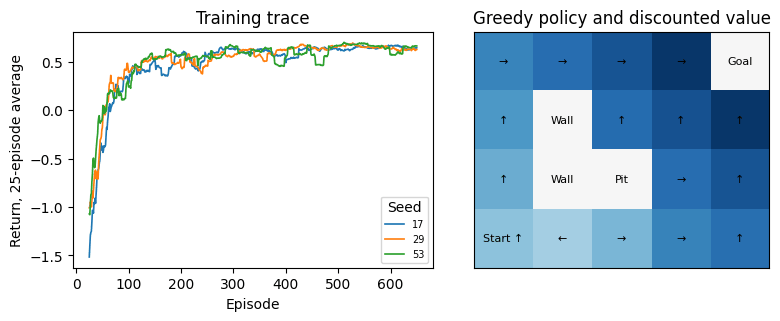

In [3]:
policies, curves = [], []
for seed in (17, 29, 53):
    policy, curve = train(seed)
    policies.append((seed, policy))
    curves.append(curve)
policy_report(policies, curves, "Return, 25-episode average", "Episode")
plt.show()

## Reading the result

The learning trace includes exploratory actions. The final policy is evaluated greedily. Variation across training seeds is reported separately from the random-policy baseline.

## References

[Sutton and Barto, Reinforcement Learning: An Introduction (2018)](https://mitpress.mit.edu/9780262039246/reinforcement-learning/)

[Grid dynamics and policy evaluation](../../../gallery/gridworld.py)